# MDFF results

Generates the paper figures from the outputs of `Train/<Backbone>/<Variant>/train.py`:

1. **Feature comparison**: MSE / RMSE / MAE / R² of the five regressors for Dense, Conv and MDFF features of each backbone.
2. **Degree of fit**: predicted vs. measured irradiance on the validation set (Random Forest on MDFF features), one panel per backbone.
3. **One-day test**: measured and predicted irradiance on 22-Jul-2018 (MobileNetV2 MDFF + polynomial regression), with a zoomed-in inset.

Run all 12 training scripts first. Figures are saved to `Results/Figures/`.

> Memory: each saved Random Forest model is ~3 GB; section 2 loads them one at a time.

In [1]:
import os
import re
from datetime import datetime

import joblib
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = os.path.abspath('..')
TRAIN_DIR = os.path.join(REPO_ROOT, 'Train')
FIG_DIR = 'Figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Folder of each configuration and the name its features are saved under
RUNS = {
    ('EfficientNetB0', 'Dense'): ('EfficientNetB0/EfficientNetDense', 'dense_efficientnetb0'),
    ('EfficientNetB0', 'Conv'):  ('EfficientNetB0/EfficientNetConv',  'conv_efficientnetb0'),
    ('EfficientNetB0', 'MDFF'):  ('EfficientNetB0/EfficientNetMDDF',  'mdff_efficientnetb0'),
    ('MobileNetV2', 'Dense'):    ('MobileNetV2/MobileNetDense',       'dense_mobilenetv2'),
    ('MobileNetV2', 'Conv'):     ('MobileNetV2/MobileConv',           'conv_mobilenetv2'),
    ('MobileNetV2', 'MDFF'):     ('MobileNetV2/MobilenetMDDF',        'mdff_mobilenetv2'),
    ('MobileNetV3s', 'Dense'):   ('MobileNetV3s/MobileDense',         'dense_mobilenetv3s'),
    ('MobileNetV3s', 'Conv'):    ('MobileNetV3s/MobileConv',          'conv_mobilenetv3s'),
    ('MobileNetV3s', 'MDFF'):    ('MobileNetV3s/MobilenetMDDF',       'mdff_mobilenetv3s'),
    ('TinyVit', 'Dense'):        ('TinyVIT/TinyVitDense',             'dense_tinyvit'),
    ('TinyVit', 'Conv'):         ('TinyVIT/TinyVitConv',              'conv_tinyvit'),
    ('TinyVit', 'MDFF'):         ('TinyVIT/TinyVitMDFF',              'mdff_tinyvit'),
}
BACKBONES = ['EfficientNetB0', 'MobileNetV2', 'MobileNetV3s', 'TinyVit']


def load_val_features(backbone, variant):
    folder, name = RUNS[(backbone, variant)]
    return np.load(os.path.join(TRAIN_DIR, folder, 'Features', 'val', f'{name}_val.npy'))


def load_model(backbone, variant, filename):
    folder, _ = RUNS[(backbone, variant)]
    return joblib.load(os.path.join(TRAIN_DIR, folder, 'models', filename))

## 1. Feature comparison

Metrics are read from the last results block of each `train.log`.

In [2]:
REGRESSORS = {
    'Linear Regression': 'Linear Regression',
    'Polynomial Regression (degree 3)': 'Polynomial Regression',
    'Decision Tree Regression': 'Decision Tree Regression',
    'Random Forest Regression': 'Random Forest Regression',
    'Support Vector Machine': 'Support Vector Regression',
}
METRICS = {'MSE': 'MSE', 'RMSE': 'RMSE', 'MAE': 'MAE', 'R2 Score': 'R2'}


def parse_log(path):
    """Return {(regressor, metric): value} from the last run recorded in train.log."""
    results, current = {}, None
    with open(path, errors='ignore') as f:
        for line in f:
            m = re.match(r'\*+ (.+?) \*+', line.strip())
            if m:
                current = REGRESSORS.get(m.group(1))
                continue
            m = re.match(r'(MSE|RMSE|MAE|R2 Score): (\S+)', line.strip())
            if m and current:
                results[(current, METRICS[m.group(1)])] = float(m.group(2))
    return results


rows = []
for (backbone, variant), (folder, _) in RUNS.items():
    for (regressor, metric), value in parse_log(os.path.join(TRAIN_DIR, folder, 'train.log')).items():
        rows.append(dict(backbone=backbone, variant=variant, regressor=regressor, metric=metric, value=value))
results = pd.DataFrame(rows)
results.to_csv('results.csv', index=False)

results.pivot_table(index=['backbone', 'variant'], columns=['metric', 'regressor'], values='value') \
       .loc[:, ['R2', 'MAE']].round(3)

metric                                       R2                    \
regressor              Decision Tree Regression Linear Regression   
backbone       variant                                              
EfficientNetB0 Conv                       0.668             0.570   
               Dense                      0.643             0.519   
               MDFF                       0.764             0.753   
MobileNetV2    Conv                       0.686             0.773   
               Dense                      0.662             0.731   
               MDFF                       0.761             0.841   
MobileNetV3s   Conv                       0.689             0.739   
               Dense                      0.655             0.702   
               MDFF                       0.775             0.844   
TinyVit        Conv                       0.711             0.796   
               Dense                      0.705             0.776   
               MDFF                       0.707             0.816   

metric                                                                 \
regressor              Polynomial Regression Random Forest Regression   
backbone       variant                                                  
EfficientNetB0 Conv              -118504.433                    0.850   
               Dense              -99018.756                    0.834   
               MDFF                 -193.485                    0.889   
MobileNetV2    Conv                    0.860                    0.856   
               Dense                   0.844                    0.848   
               MDFF                    0.890                    0.887   
MobileNetV3s   Conv                    0.854                    0.849   
               Dense                   0.845                    0.837   
               MDFF                    0.894                    0.892   
TinyVit        Conv                    0.867                    0.861   
               Dense                   0.859                    0.859   
               MDFF                    0.871                    0.864   

metric                                                                MAE  \
regressor              Support Vector Regression Decision Tree Regression   
backbone       variant                                                      
EfficientNetB0 Conv                        0.520                   93.147   
               Dense                       0.415                   97.666   
               MDFF                        0.726                   75.754   
MobileNetV2    Conv                        0.771                   90.162   
               Dense                       0.730                   93.877   
               MDFF                        0.839                   75.243   
MobileNetV3s   Conv                        0.735                   85.100   
               Dense                       0.701                   90.996   
               MDFF                        0.841                   72.024   
TinyVit        Conv                        0.793                   84.718   
               Dense                       0.774                   85.513   
               MDFF                        0.816                   86.636   

metric                                                          \
regressor              Linear Regression Polynomial Regression   
backbone       variant                                           
EfficientNetB0 Conv              123.750               339.667   
               Dense             131.176               454.004   
               MDFF               91.525                68.588   
MobileNetV2    Conv               86.697                62.789   
               Dense              94.449                66.562   
               MDFF               70.888                53.669   
MobileNetV3s   Conv               92.183                62.269   
               Dense             100.321            

In [3]:
def plot_comparisons(dense, conv, mdff, plt, title='', y_lab = '', metric = 'MSE'):
	# set width of bar 
	barWidth = 0.2

	# Set position of bar on X axis 
	br1 = np.arange(len(dense)) 
	br2 = [x + barWidth for x in br1] 
	br4 = [x + barWidth for x in br2]

	# Make the plot 
	plt.bar(br1, dense, color ='#F72585', width = barWidth, 
			edgecolor ='grey', label ='Dense') 
	plt.bar(br2, conv, color ='#3A0CA3', width = barWidth, 
			edgecolor ='grey', label ='Conv')  
	plt.bar(br4, mdff, color ='#4CC9F0', width = barWidth, 
			edgecolor ='grey', label ='MDFF') 

	plt.set_title(title, fontsize = 18)
	# Adding Xticks 
	plt.set_ylabel(y_lab, fontweight ='bold', fontsize = 15) 
	plt.set_xticks([r + barWidth for r in range(len(dense))], 
			['EfficientNetB0', 'MobileNetV2', 'MobileNetV3s', 'TinyVit'], fontsize = 10)
	if metric == 'MSE':
		plt.set_ylim(0, 50000)
	elif metric == 'RMSE':
		plt.set_ylim(0, 1000)
	elif metric == 'MAE':
		plt.set_ylim(0, 150)
	elif metric == 'R2':
		plt.set_ylim(0, 1)

	plt.legend(fontsize = 12, loc='upper left')

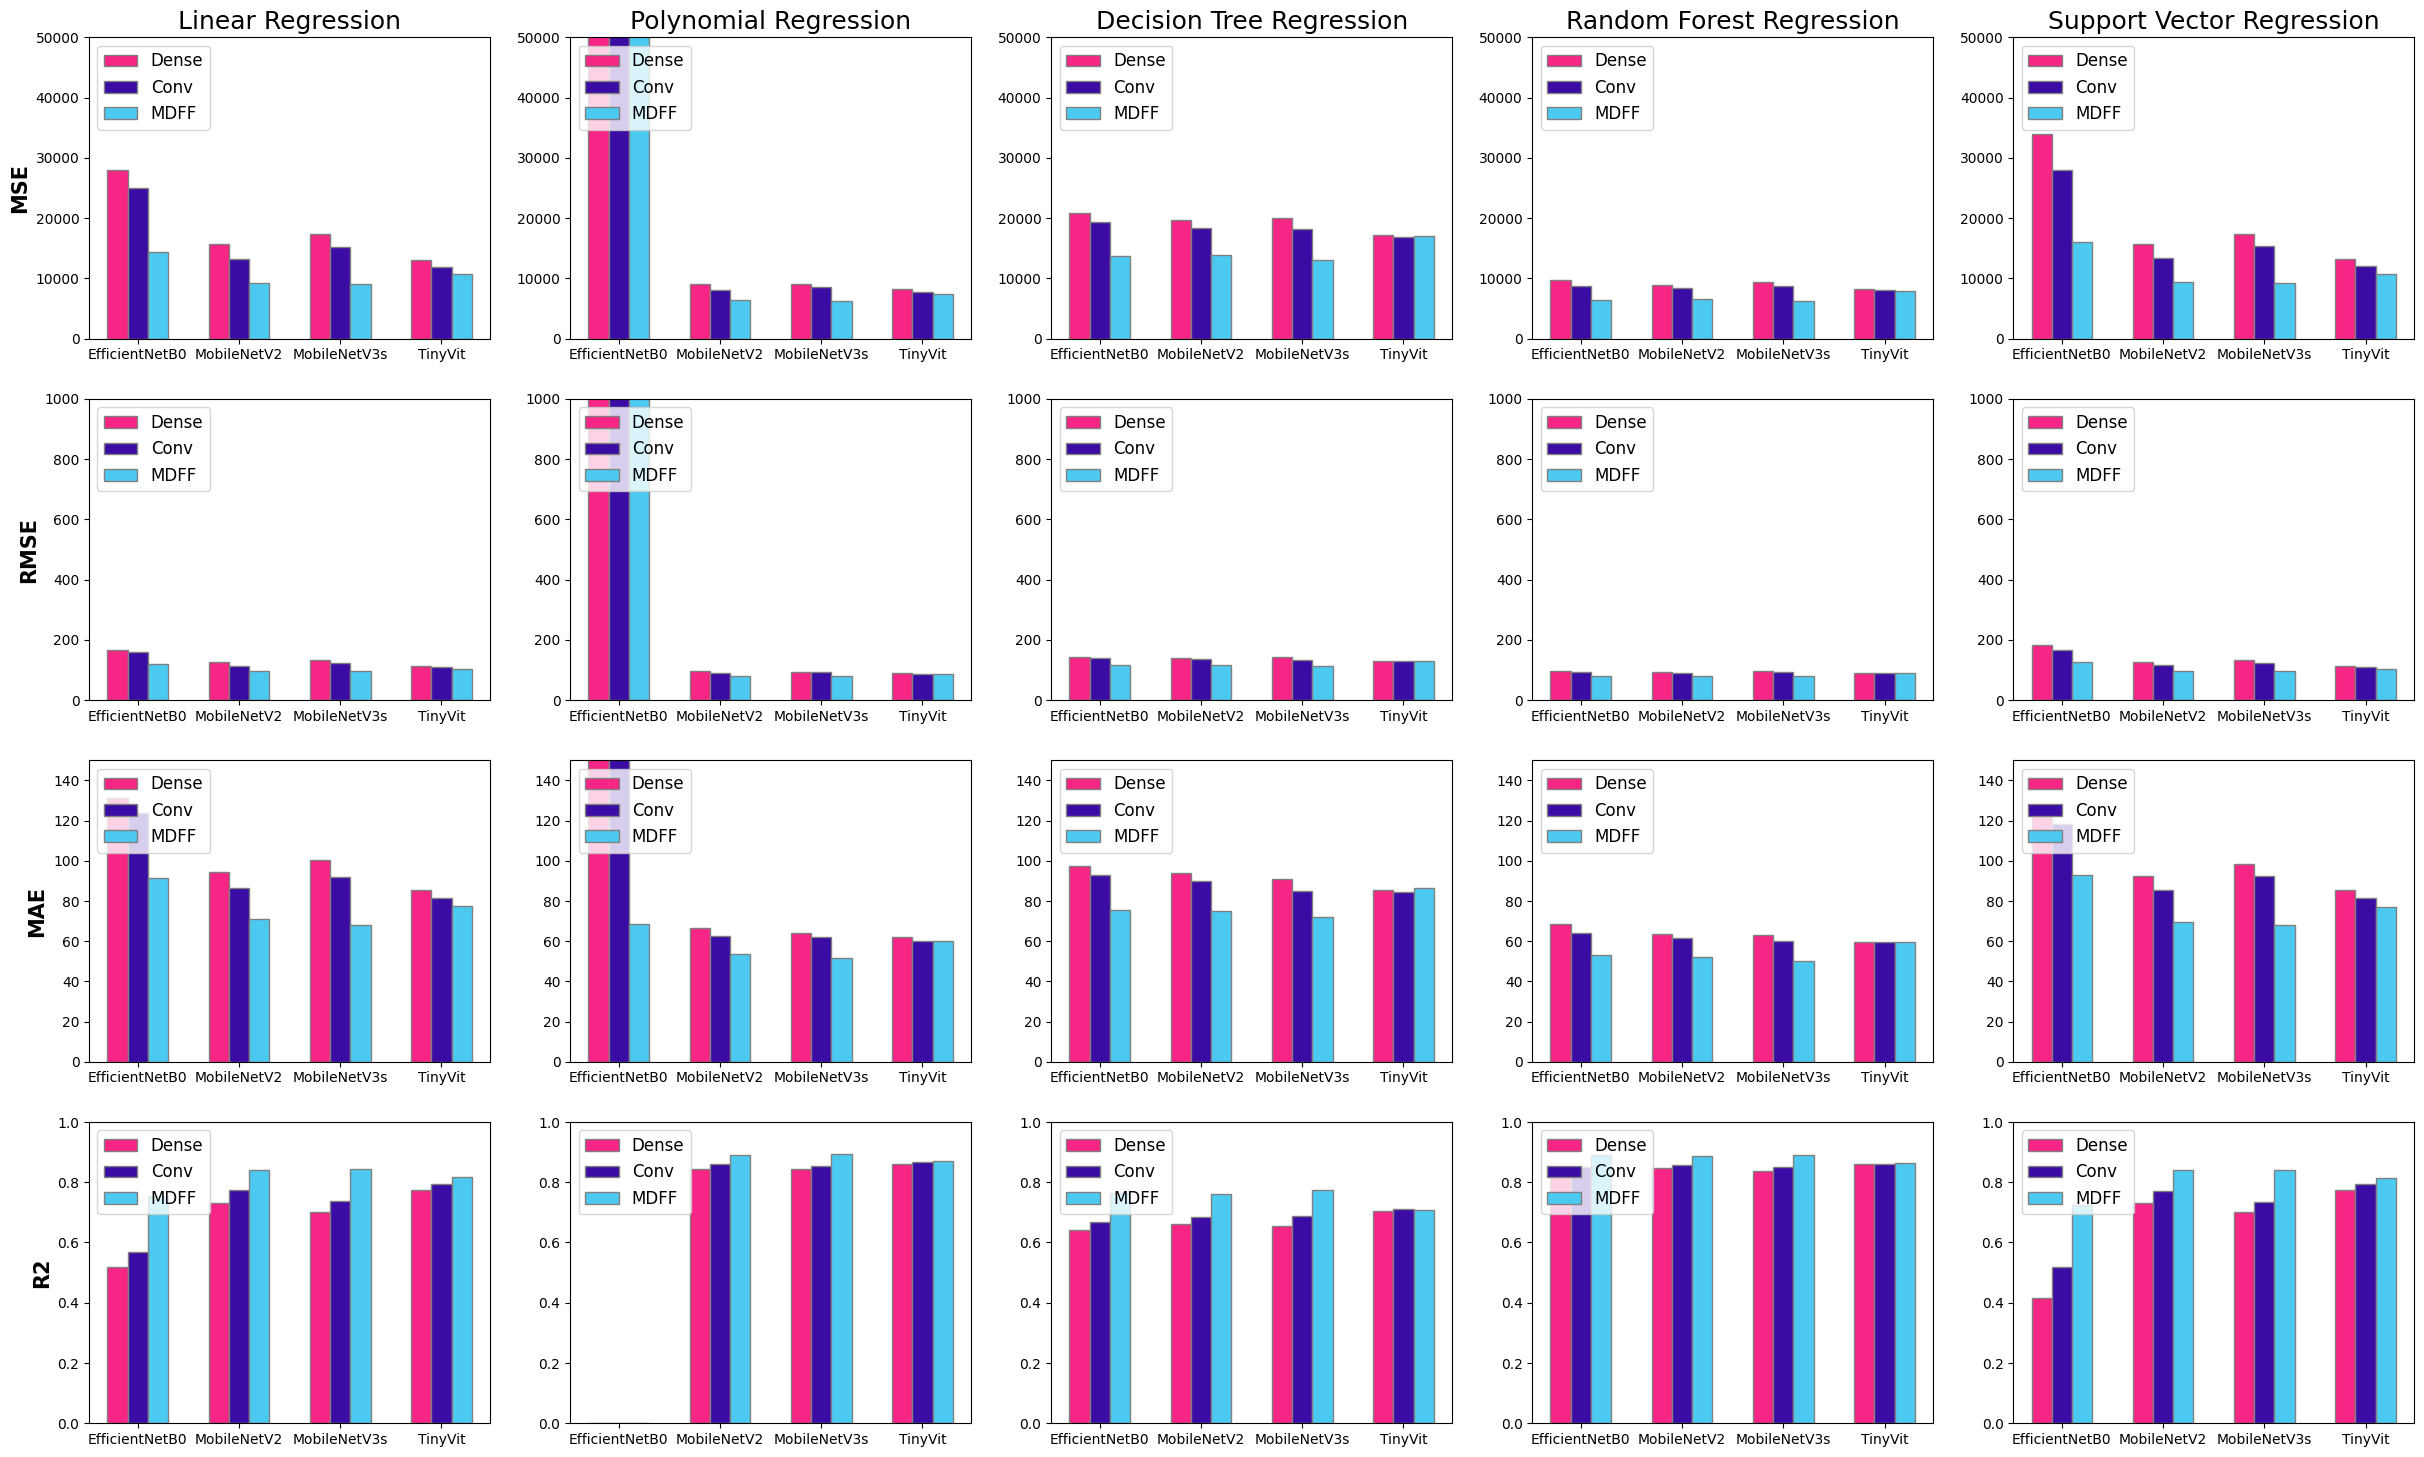

In [4]:
def values(variant, regressor, metric):
    sel = results[(results.variant == variant) & (results.regressor == regressor) & (results.metric == metric)]
    return [sel[sel.backbone == b].value.item() for b in BACKBONES]


# Increase the size of the figure
f, ax = plt.subplots(4, 5, figsize=(30, 18))

for i, metric in enumerate(['MSE', 'RMSE', 'MAE', 'R2']):
    for j, regressor in enumerate(REGRESSORS.values()):
        plot_comparisons(values('Dense', regressor, metric), values('Conv', regressor, metric),
                         values('MDFF', regressor, metric), ax[i, j],
                         title=regressor if i == 0 else '', y_lab=metric if j == 0 else '', metric=metric)

f.savefig(os.path.join(FIG_DIR, 'feature-comparison.png'), dpi=300, bbox_inches='tight')

## 2. Degree of fit

Degree of fit between the actual and predicted irradiance values using the proposed method with Random Forest Regressor. (a), (b), (c) and (d) denote the performance while trained on EfficientNet-B0, MobileNetV2, MobileNetV3-Small, and TinyViT features. Every 500th validation sample is shown, coloured by how close the prediction is to the measurement.

In [5]:
def plot_degree_of_fit(reducted_val_features, predictions, title, ax):
    x = reducted_val_features[::500, -1]
    y = predictions[::500]

    # Calculate the MSE of each point
    goodness_scores = np.sqrt((x - y) ** 2)

    inverted_scores = max(goodness_scores)  - goodness_scores

    # Normalize the inverted goodness scores to be between 0 and 1
    norm = mcolors.Normalize(vmin=min(inverted_scores), vmax=max(inverted_scores))

    m, b = np.polyfit(x, y, 1)
    xd = np.linspace(0, 1250)
    yd = m*xd + b
    # Create a scatter plot where the color intensity depends on the inverted goodness score
    ax.scatter(x, y, c=inverted_scores, cmap='Purples', norm=norm)
    ax.plot(xd, yd, '-r')
    # Customize the plot
    ax.set_xlabel("Actual Solar Irradiance (W/m$^2$)")
    ax.set_ylabel("Predicted Solar Irradiance (W/m$^2$)")
    ax.set_title(title)

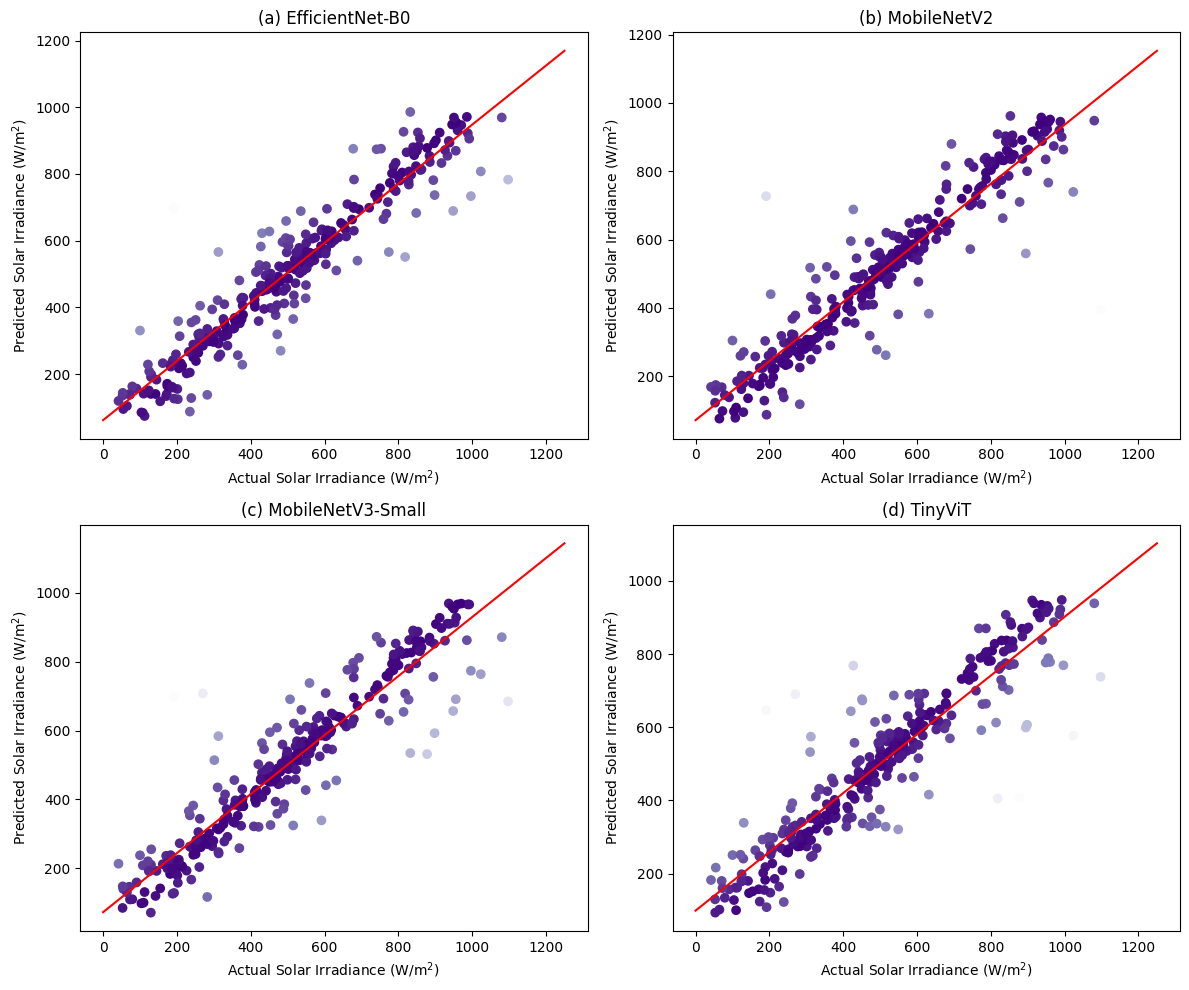

In [6]:
PANEL_NAMES = {'EfficientNetB0': 'EfficientNet-B0', 'MobileNetV2': 'MobileNetV2',
               'MobileNetV3s': 'MobileNetV3-Small', 'TinyVit': 'TinyViT'}

f, axes = plt.subplots(2, 2, figsize=(12, 10))

for letter, backbone, ax in zip('abcd', BACKBONES, axes.flat):
    reducted_val_features = load_val_features(backbone, 'MDFF')
    model = load_model(backbone, 'MDFF', 'random_forest_model.pkl')
    predictions = model.predict(reducted_val_features[:, :-1])
    del model  # ~3 GB each, free before loading the next

    plot_degree_of_fit(reducted_val_features, predictions, f'({letter}) {PANEL_NAMES[backbone]}', ax)

f.tight_layout()
f.savefig(os.path.join(FIG_DIR, 'degree-of-fit.jpg'), dpi=300, bbox_inches='tight')
plt.show()

## 3. One-day test (22-Jul-2018)

Measured weather-station irradiance (violet) and MobileNetV2 MDFF + polynomial-regression predictions (blue). The inset zooms in on rapid fluctuations.

In [7]:
def visualize_data(img_times, predictions, reducted_val_features, title=''):
    # Generating a dataset with Unix time (in seconds) as the x-axis
    skip = 3
    time_in_seconds = img_times[::skip]
    pred = predictions[::skip]
    target = reducted_val_features[:, -1][::skip]

    # Converting Unix time to a format matplotlib can work with
    dates = [datetime.utcfromtimestamp(ts) for ts in time_in_seconds]

    # Create the main plot
    plt.figure(figsize=(15, 6))
    plt.plot(dates, pred, label='Predicted Irradiance')
    plt.plot(dates, target, label='Actual Irradiance', color='#3A0CA3') 
    plt.legend()
    plt.xlabel('Time')
    plt.ylabel("Solar Irradiance Value(W/m$^2$)")

    # Formatting the date on the x-axis to make it more readable
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m-%d %H:%M:%S'))
    plt.gca().xaxis.set_major_locator(mdates.HourLocator())
    plt.gcf().autofmt_xdate()  # Rotation

    plt.title(title)

    # Create the inset plot for the first hour
    first_hour_dates = dates[240:300]  # Assuming 1 data point every 15 seconds
    first_hour_pred = pred[240:300]
    first_hour_target = target[240:300]

    inset_axes = plt.axes([0.5, 0.3, 0.25, 0.25])  # Adjust position and size as needed
    # Show the plots
    inset_axes.plot(first_hour_dates, first_hour_pred, label='Predicted')
    inset_axes.plot(first_hour_dates, first_hour_target, label='Actual', color='#3A0CA3')
    inset_axes.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M:%S'))
    inset_axes.xaxis.set_major_locator(mdates.MinuteLocator(interval=15))  # Tick marks every 15 minutes

    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, title + '.jpg'), dpi=300, bbox_inches='tight')
    plt.show()

/tmp/ipykernel_135569/887258298.py:38: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


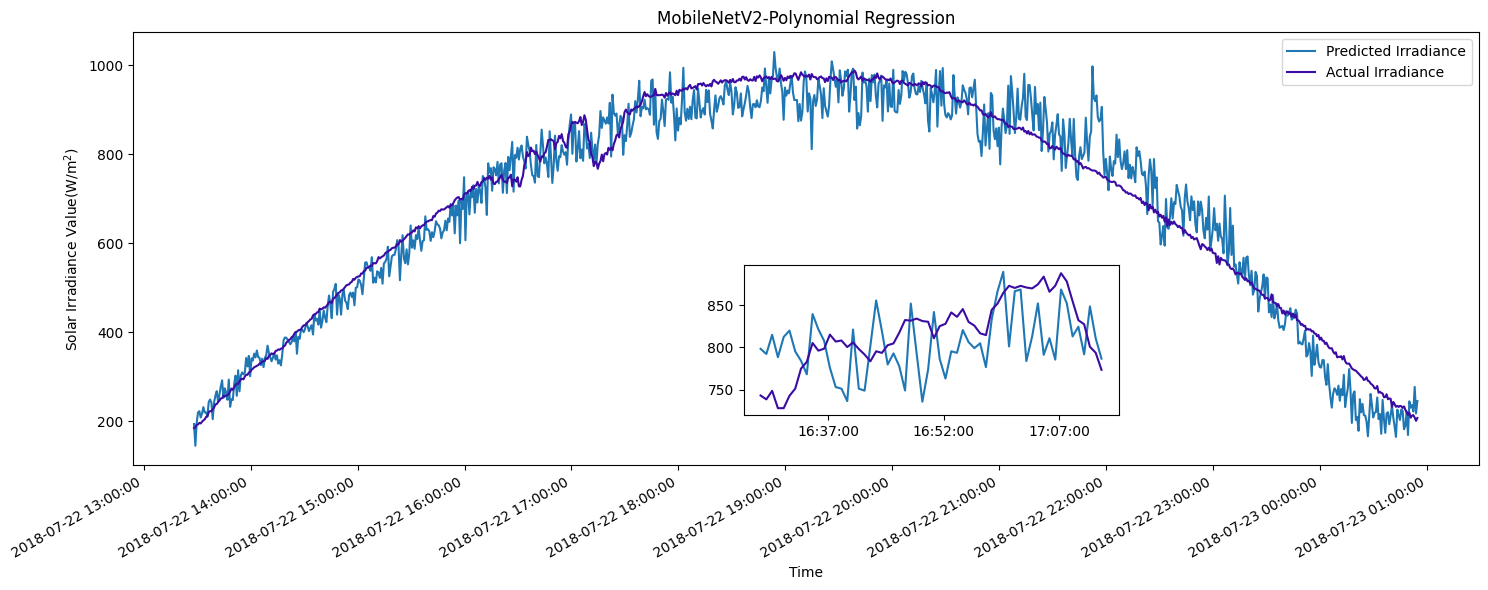

In [8]:
DAY = '2018_07_22'

# Validation rows are the last 30% of data/girasol.csv.gz, in file order (same as train.py)
data = pd.read_csv(os.path.join(REPO_ROOT, 'data', 'girasol.csv.gz'))
val_names = data['name'].iloc[int(0.7 * len(data)):].reset_index(drop=True)

val_features = load_val_features('MobileNetV2', 'MDFF')
val_names = val_names.iloc[:len(val_features)]  # train.py drops a final chunk smaller than 20 rows
day = val_names.str.startswith(DAY).to_numpy()
reducted_val_features = val_features[day]

# Image timestamps (Unix seconds) come from the file names, e.g. 1532246400IR.png
img_times = val_names[day].str.extract(r'(\d+)IR\.png$')[0].astype(int).to_numpy()

loaded_model, loaded_poly_features = load_model('MobileNetV2', 'MDFF', 'polynomial_regression_model_degree_3.pkl')
M_predictions = loaded_model.predict(loaded_poly_features.transform(reducted_val_features[:, :-1]))

visualize_data(img_times, M_predictions, reducted_val_features, title='MobileNetV2-Polynomial Regression')